# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Rendeiro 2020's CLL malignant manifold is **non-branching**: the three embryonic developmental
signatures (gastrulation / posterior somitogenesis / neural crest) fall onto a **single axis** rather
than resolving into two competing arms. A PPT *tree* over this compact near-round cloud fabricates
spurious forks (the branching machinery invents bifurcations where the data is one blob); an ElPiGraph
*curve* returns a clean, fold-free 2-tip backbone. We therefore fit a **curve**, not a tree, keep every
cell on its original joint embedding (no re-embedding of a linear compartment), root at the
Gast/pSom-high developmental origin (Crest is *late*), and check the curve for folds. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells stay on their original joint-embedding coordinates (no re-embedding). The three embryonic
signatures are scored against the shared **union** control pool, then **graph-smoothed** (3 rounds of
kNN-connectivity averaging) for reading geography and correlations. The raw per-cell scores are kept
for the deliverable signature UMAPs in 03 (10x dropout must remain visible there).

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f} (near-round compact cloud)')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 18491 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.30 (near-round compact cloud)
Gast: 53/81 genes present
pSom: 53/98 genes present
Crest: 69/104 genes present


### Scope decision — whole manifold (proliferation diffuse, axis developmental)
CLL is partly cycling but the proliferative signal is diffuse (single Leiden lobe in 01), so there is
no proliferative compartment to scope out. We confirm the developmental axis is not a cell-cycle
confound: the Gast/pSom/Crest module gene sets barely overlap the cell-cycle programme and the smoothed
scores correlate near-zero with the cycling score. The whole manifold is therefore carried into the
trajectory.

In [4]:
cc_genes = set(adata.uns.get('cc_genes', [])) if 'cc_genes' in adata.uns else set()
s_genes=set(['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8','HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA'])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    gs = set(pd.read_csv(os.path.join(pth_feat,src+'.csv')).hsapiens.dropna())
    print(f'{lab}: {len(gs & s_genes)}/{len(gs)} genes overlap the cell-cycle programme')
cyc = np.maximum(pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0),
                 pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0))
for lab in ['Gast','pSom','Crest']:
    print(f'corr({lab}_sm, cycling) = {np.corrcoef(adata.obs[lab+"_sm"], cyc)[0,1]:+.3f}')
print('-> developmental axis is not a cell-cycle confound; keep whole manifold (no scoping).')
sub = adata

Gast: 0/81 genes overlap the cell-cycle programme
pSom: 2/98 genes overlap the cell-cycle programme
Crest: 0/104 genes overlap the cell-cycle programme
corr(Gast_sm, cycling) = -0.015
corr(pSom_sm, cycling) = +0.001
corr(Crest_sm, cycling) = -0.010
-> developmental axis is not a cell-cycle confound; keep whole manifold (no scoping).


### Topology probe — PPT tree forks vs principal curve
A PPT *tree* over this compact cloud invents forks (unstable tip/fork counts across node settings -> a
single blob, not a real bifurcation); an ElPiGraph *curve* returns a clean 2-tip / 0-fork backbone with
a node self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes exceeds the median
edge length -> fold-free). The curve is therefore the correct model.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for N in [100,150,200]:
    ad = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    B=np.asarray(ad.uns['graph']['B']); tips=int(((B>0).sum(0)==1).sum()); forks=int(((B>0).sum(0)>=3).sum())
    print(f'PPT tree N={N}: {tips} tips, {forks} forks (spurious -> not a real bifurcation)')
for N in [15,20,30]:
    ad = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(ad, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(ad)
    print(f'curve N={N}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
print('chosen: curve N=20 (2 tips, 0 forks, fold-free)')

PPT tree N=100: 6 tips, 4 forks (spurious -> not a real bifurcation)
PPT tree N=150: 9 tips, 7 forks (spurious -> not a real bifurcation)
PPT tree N=200: 9 tips, 7 forks (spurious -> not a real bifurcation)
curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.80
curve N=30: 2 tips, 0 forks | self-approach 2.31
chosen: curve N=20 (2 tips, 0 forks, fold-free)


In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'fitted curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

fitted curve: 2 tips, 0 forks | fold self-approach ratio = 2.80 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(Gast/pSom is *early*, Crest is *late*; never root at Crest or a proliferation state). Pseudotime then
flows toward the neural-crest terminus.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn=(t-t.min())/(t.max()-t.min())
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'  {m}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0182 pSom=+0.0071 Crest=+0.0073
tip 2: Gast=-0.0157 pSom=+0.0047 Crest=+0.0069
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.624 p=0.0e+00
  pSom_sm: rho=+0.490 p=0.0e+00
  Crest_sm: rho=+0.079 p=5.5e-27
  Gast_sm-high decile mean pseudotime = 0.30
  pSom_sm-high decile mean pseudotime = 0.96
  Crest_sm-high decile mean pseudotime = 0.73


### Reorient to house style (pseudotime left -> right)
Fix the sign of the house orientation (derived in 01) so low pseudotime sits on the left. This is a
discrete sign choice on the already-rotated `X_umap_lin` coordinates — no new rotation, no re-embedding.

In [8]:
xyr = sub.obsm['X_umap_lin'].copy(); t = sub.obs['t'].values
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: pseudotime left->right; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: pseudotime left->right; corr(x_lin, pseudotime) = +0.95


### Save manifold + trajectory figure (deliverable) — house style `(3.5,1.5)`, cividis

saved manifold.h5ad + manifold.pdf


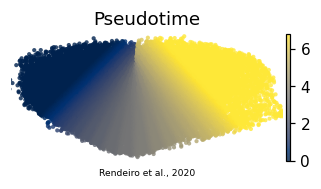

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')